In [1]:
import os
import joblib
import optuna
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

import warnings
warnings.filterwarnings('ignore')
optuna.logging.set_verbosity(optuna.logging.WARNING)

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.size'] = 11
plt.rcParams['figure.figsize'] = (10, 6)


C:\Users\sahil kavishka\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
data_path = '../data/proccessed/processed_dataset.csv'
if not os.path.exists(data_path):
    data_path = 'data/proccessed/processed_dataset.csv'

df = pd.read_csv(data_path)
print("Dataset shape:", df.shape)
df.head(3)


Dataset shape: (7043, 1163)


,Latitude,Longitude,Senior Citizen,Partner,Dependents,Tenure Months,Phone Service,Paperless Billing,Monthly Charges,Total Charges,...,Tech Support_Yes,Streaming TV_No internet service,Streaming TV_Yes,Streaming Movies_No internet service,Streaming Movies_Yes,Contract_One year,Contract_Two year,Payment Method_Credit card (automatic),Payment Method_Electronic check,Payment Method_Mailed check
0,33.964131,-118.272783,0,0,0,2,1,1,53.85,108.15,...,0,0,0,0,0,0,0,0,0,1
1,34.059281,-118.307420,0,0,1,2,1,1,70.70,151.65,...,0,0,0,0,0,0,0,0,1,0
2,34.048013,-118.293953,0,0,1,8,1,1,99.65,820.50,...,0,0,1,0,1,0,0,0,1,0


In [3]:
y = df['Churn Value']

# Drop target and post-event leakage column
drop_cols = ['Churn Value']
if 'Churn Reason' in df.columns:
    drop_cols.append('Churn Reason')

X = df.drop(columns=drop_cols)

# Scale numeric columns
continuous_cols = [col for col in ['Latitude', 'Longitude', 'Tenure Months', 'Monthly Charges', 'Total Charges'] if col in X.columns]
scaler = StandardScaler()
X[continuous_cols] = scaler.fit_transform(X[continuous_cols])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"X_train: {X_train.shape}, X_test: {X_test.shape}")


X_train: (5634, 1161), X_test: (1409, 1161)


In [4]:
scale_pos = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': LogisticRegression(max_iter=2000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1),
    'XGBoost': XGBClassifier(n_estimators=100, scale_pos_weight=scale_pos, eval_metric='logloss', random_state=42, n_jobs=-1)
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

for name, model in models.items():
    scores = cross_validate(
        model, X_train, y_train, cv=cv,
        scoring=['accuracy', 'precision', 'recall', 'f1', 'roc_auc'],
        n_jobs=-1
    )
    cv_results[name] = {
        'CV Accuracy': scores['test_accuracy'].mean(),
        'CV Recall': scores['test_recall'].mean(),
        'CV Precision': scores['test_precision'].mean(),
        'CV F1-Score': scores['test_f1'].mean(),
        'CV ROC-AUC': scores['test_roc_auc'].mean()
    }

pd.DataFrame(cv_results).T.round(4)


,CV Accuracy,CV Recall,CV Precision,CV F1-Score,CV ROC-AUC
Logistic Regression,0.7584,0.7759,0.5307,0.6302,0.8478
Random Forest,0.8051,0.5117,0.6763,0.5823,0.8493
XGBoost,0.7803,0.6970,0.5707,0.6274,0.8444


In [5]:
fitted_models = {}
test_metrics = []
predictions = {}
probabilities = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model
    
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]
    
    predictions[name] = y_pred
    probabilities[name] = y_prob
    
    test_metrics.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision': precision_score(y_test, y_pred),
        'Recall': recall_score(y_test, y_pred),
        'F1-Score': f1_score(y_test, y_pred),
        'ROC-AUC': roc_auc_score(y_test, y_prob)
    })

comparison_df = pd.DataFrame(test_metrics).set_index('Model')
comparison_df.round(4)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Logistic Regression,0.7473,0.5165,0.7540,0.6130,0.8354
Random Forest,0.8013,0.6599,0.5187,0.5808,0.8452
XGBoost,0.7608,0.5378,0.7032,0.6095,0.8331


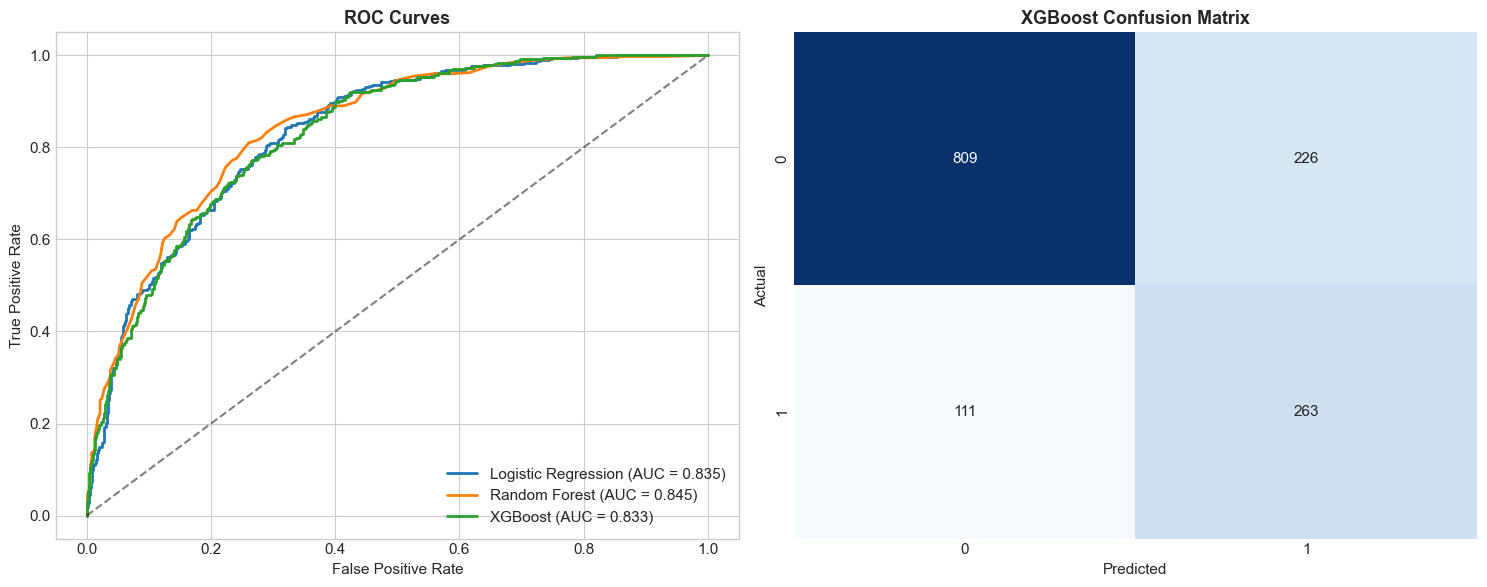

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

for name in models.keys():
    fpr, tpr, _ = roc_curve(y_test, probabilities[name])
    auc_val = roc_auc_score(y_test, probabilities[name])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc_val:.3f})", linewidth=2)

axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[0].set_title('ROC Curves', fontsize=13, fontweight='bold')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')

cm = confusion_matrix(y_test, predictions['XGBoost'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False)
axes[1].set_title('XGBoost Confusion Matrix', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()


In [7]:
def objective(trial):
    params = {
        'n_estimators': trial.suggest_int('n_estimators', 50, 150),
        'max_depth': trial.suggest_int('max_depth', 3, 6),
        'learning_rate': trial.suggest_float('learning_rate', 0.02, 0.2, log=True),
        'subsample': trial.suggest_float('subsample', 0.7, 1.0),
        'colsample_bytree': trial.suggest_float('colsample_bytree', 0.7, 1.0),
        'scale_pos_weight': scale_pos,
        'eval_metric': 'logloss',
        'random_state': 42,
        'n_jobs': -1
    }
    clf = XGBClassifier(**params)
    clf.fit(X_train, y_train)
    prob = clf.predict_proba(X_test)[:, 1]
    return roc_auc_score(y_test, prob)

study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=15)

print("Best Optuna ROC-AUC:", round(study.best_value, 4))
print("Best Hyperparameters:", study.best_params)


Best Optuna ROC-AUC: 0.8579
Best Hyperparameters: {'n_estimators': 72, 'max_depth': 6, 'learning_rate': 0.03403230943036267, 'subsample': 0.713745045340417, 'colsample_bytree': 0.8120580542184777}


In [8]:
best_params = study.best_params
best_params['scale_pos_weight'] = scale_pos
best_params['eval_metric'] = 'logloss'
best_params['random_state'] = 42

tuned_xgb = XGBClassifier(**best_params)
tuned_xgb.fit(X_train, y_train)

y_pred_tuned = tuned_xgb.predict(X_test)
y_prob_tuned = tuned_xgb.predict_proba(X_test)[:, 1]

tuned_results = pd.DataFrame([{
    'Model': 'Tuned XGBoost (Optuna)',
    'Accuracy': accuracy_score(y_test, y_pred_tuned),
    'Precision': precision_score(y_test, y_pred_tuned),
    'Recall': recall_score(y_test, y_pred_tuned),
    'F1-Score': f1_score(y_test, y_pred_tuned),
    'ROC-AUC': roc_auc_score(y_test, y_prob_tuned)
}]).set_index('Model')

tuned_results.round(4)


,Accuracy,Precision,Recall,F1-Score,ROC-AUC
Model,,,,,
Tuned XGBoost (Optuna),0.7615,0.5337,0.8048,0.6418,0.8579


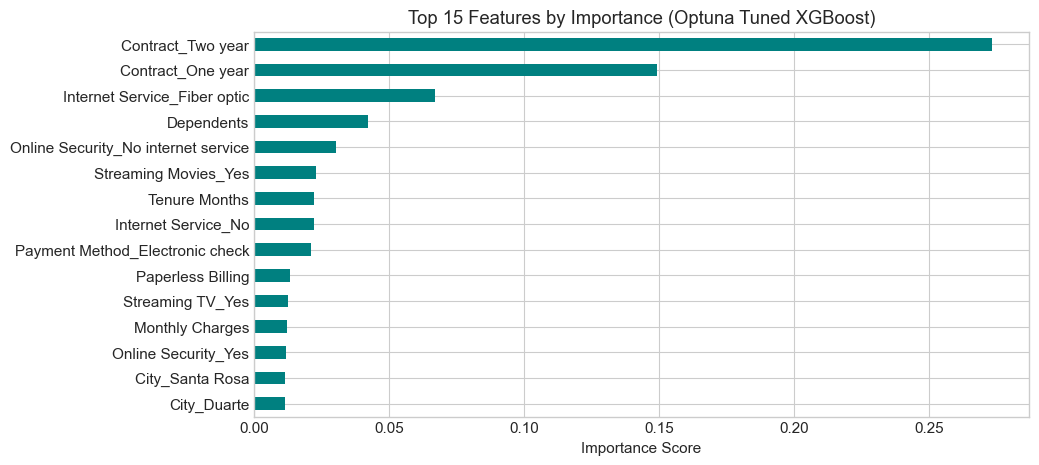

Top 5 Churn Drivers:
Contract_Two year                      0.273421
Contract_One year                      0.149127
Internet Service_Fiber optic           0.066900
Dependents                             0.042073
Online Security_No internet service    0.030325
dtype: float32


In [9]:
importances = tuned_xgb.feature_importances_
feat_imp = pd.Series(importances, index=X.columns).sort_values(ascending=False)

plt.figure(figsize=(10, 5))
feat_imp.head(15).plot(kind='barh', color='teal').invert_yaxis()
plt.title('Top 15 Features by Importance (Optuna Tuned XGBoost)')
plt.xlabel('Importance Score')
plt.show()

print("Top 5 Churn Drivers:")
print(feat_imp.head(5))


In [10]:
os.makedirs('../src/churn_predictor/models', exist_ok=True)
model_path = '../src/churn_predictor/models/best_churn_model.joblib'
joblib.dump(tuned_xgb, model_path)
print(f"Saved best model to: {model_path}")


Saved best model to: ../src/churn_predictor/models/best_churn_model.joblib
